# Kamień–papier–nożyce na UNIHIKER K10: trening BEZ własnych zdjęć

Ta wersja nie potrzebuje zdjęć z kamery K10. Zamiast tego **przerabia gotowy zbiór z Kaggle**,
żeby wyglądał jak obraz z płytki:

1. **Wycina dłonie z zielonego tła** (green screen, progowanie koloru w HSV).
2. **Wkleja je na losowe tła:** zdjęcia (fragmenty zdjęć kwiatów/roślin z TensorFlow,
   opcjonalnie Twój własny folder z tłami) i tła generowane (ściana + biurko, gradienty,
   rozmyte przedmioty, tkaniny).
3. **Ustawia dłoń jak przed kamerą K10:** ręka wchodzi do kadru od dołu (czasem z boku),
   ma różny rozmiar, położenie i obrót.
4. **Udaje kamerę K10:** balans bieli, gamma, ekspozycja, rozmycie, szum, zmniejszenie
   240→96 przez uśrednianie bloków (jak na płytce) i redukcja kolorów do RGB565.

Dalej wszystko jest jak w zwykłym notebooku: MobileNetV2 0.35, 96×96, kwantyzacja INT8 i plik `model_data.h`.

**Kaggle:**
- Settings → *Internet: On* (wagi ImageNet i zdjęcia na tła),
- dodaj dataset `drgfreeman/rockpaperscissors` (Add Input),
- GPU T4 przyspiesza trening, ale nie jest wymagane.

In [ ]:
import os, sys, glob, math, random, subprocess, importlib
import numpy as np
print("NumPy", np.__version__)

# Na Kaggle zdarza się, że preinstalowany OpenCV jest skompilowany pod NumPy 2.x, a środowisko ma
# NumPy 1.x (błąd "numpy._core.multiarray failed to import"). Wtedy doinstalowujemy obok wersję
# OpenCV zgodną z obiema wersjami NumPy, bez ruszania NumPy ani TensorFlow.
def importuj_cv2():
    try:
        import cv2
        return cv2
    except ImportError as e:
        print("OpenCV nie pasuje do tej wersji NumPy:", e)
        print("Instaluję zgodny OpenCV (opencv-python-headless 4.10.0.84) do /tmp/cv2fix ...")
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--no-deps",
                        "--target", "/tmp/cv2fix", "opencv-python-headless==4.10.0.84"], check=True)
        for m in [m for m in list(sys.modules) if m == "cv2" or m.startswith("cv2.")]:
            del sys.modules[m]
        sys.path.insert(0, "/tmp/cv2fix")
        importlib.invalidate_caches()
        import cv2
        return cv2

cv2 = importuj_cv2()
import tensorflow as tf
import keras
from keras import layers
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt

print("TensorFlow", tf.__version__, "| Keras", keras.__version__, "| OpenCV", cv2.__version__)

## 1. Ustawienia

In [2]:
IMG = 128                 # wejście modelu (musi się zgadzać z MODEL_IMG na K10)
KADR = 240               # K10 wycina z kamery kwadrat 240x240 i zmniejsza go do 96x96
ALPHA = 0.35
BATCH = 32
EPOCHS_HEAD = 10
EPOCHS_FINE = 10
CLASSES = ["paper", "rock", "scissors"]   # kolejność = kolejność etykiet na K10

# Folder, w którym są podfoldery paper/, rock/, scissors/.
# Na Kaggle: "/kaggle/input/rockpaperscissors/rps-cv-images".
# W lokalnym Jupyterze: ścieżka WZGLĘDEM FOLDERU NOTEBOOKA albo pełna ścieżka na dysku.
# Uwaga: "Copy Path" w JupyterLab daje ścieżkę względem folderu startowego Jupytera, nie notebooka.
# Jeśli ścieżka jest zła, notebook sam poszuka folderu z paper/rock/scissors w pobliżu.
KAGGLE_DIR = "/kaggle/input/rockpaperscissors/rps-cv-images"
WARIANTY_NA_DLON = 6     # ile sztucznych zdjęć z jednej dłoni na JEDNĄ epokę (sceny są losowane od nowa co epokę)
ROZMIAR_DLONI = 160      # dłuższy bok przechowywanej wyciętej dłoni (mniej = mniej RAM)
LICZBA_ZDJEC_TLA = 300   # ile zdjęć na tła trzymać w pamięci (mniej = mniej RAM)
CZESC_WALIDACJI = 0.15   # walidacja na dłoniach, których model nie widział w treningu
POBIERZ_ZDJECIA_TLA = True   # fragmenty zdjęć z flower_photos (TensorFlow) jako realistyczne tła
BG_DIR = ""              # opcjonalnie: własny folder ze zdjęciami na tła (np. dataset wnętrz z Kaggle)
K10_TEST_DIR = ""        # opcjonalnie: kilka zdjęć z K10 (paper/rock/scissors) TYLKO do sprawdzenia modelu
SEED = 42
OUT_DIR = "/kaggle/working" if os.path.isdir("/kaggle/working") else "."

def ma_klasy(folder):
    return all(os.path.isdir(os.path.join(folder, c)) for c in CLASSES)

def znajdz_zbior(sciezka, max_glebokosc=6):
    kandydaci = [sciezka, sciezka.lstrip("/"), os.path.join(os.getcwd(), sciezka.lstrip("/"))]
    for k in kandydaci:
        if k and ma_klasy(k):
            return os.path.abspath(k)
    print(f"Nie ma folderu {sciezka!r} (bieżący folder: {os.getcwd()}). Szukam zbioru w pobliżu...")
    for baza in [os.getcwd(), os.path.dirname(os.getcwd()), os.path.expanduser("~"), "/kaggle/input"]:
        if not os.path.isdir(baza):
            continue
        for root, dirs, _ in os.walk(baza):
            dirs[:] = [d for d in dirs if not d.startswith(".") and d not in ("site-packages", "node_modules")]
            if root[len(baza):].count(os.sep) >= max_glebokosc:
                dirs[:] = []
            if ma_klasy(root):
                return os.path.abspath(root)
    raise FileNotFoundError("Nie znalazłam folderu z podfolderami paper/, rock/, scissors/. "
                            "Wpisz pełną ścieżkę w KAGGLE_DIR.")

KAGGLE_DIR = znajdz_zbior(KAGGLE_DIR)
print("Zbiór:", KAGGLE_DIR)
for c in CLASSES:
    print(f"  {c}: {len(os.listdir(os.path.join(KAGGLE_DIR, c)))} plików")

rng = np.random.default_rng(SEED)
random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

Nie ma folderu '/kaggle/input/rockpaperscissors/rps-cv-images' (bieżący folder: /home/jovyan/lab/K10/kaggle/working). Szukam zbioru w pobliżu...
Zbiór: /home/jovyan/lab/K10/kaggle/input/rps-cv-images
  paper: 712 plików
  rock: 726 plików
  scissors: 750 plików


## 2. Wycinanie dłoni z zielonego tła

Tło to piksele o zielonym odcieniu, wystarczającym nasyceniu i jasności. Z maski zostawiamy
tylko duże fragmenty (dłoń z ręką) i lekko wygładzamy krawędź. Zielona poświata na brzegach
dłoni jest usuwana (*despill*). Na koniec każdą dłoń obracamy tak, żeby ręka wchodziła od dołu.

In [3]:
H_MIN, H_MAX = 35, 95    # zakres odcienia zieleni w OpenCV (0–180)
S_MIN, V_MIN = 60, 30

def wytnij_dlon(bgr):
    hsv = cv2.cvtColor(bgr, cv2.COLOR_BGR2HSV)
    h, s, v = cv2.split(hsv)
    tlo = (h >= H_MIN) & (h <= H_MAX) & (s >= S_MIN) & (v >= V_MIN)
    maska = (~tlo).astype(np.uint8) * 255
    maska = cv2.morphologyEx(maska, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))
    maska = cv2.morphologyEx(maska, cv2.MORPH_CLOSE, np.ones((5, 5), np.uint8))
    # zostaw tylko duże spójne fragmenty (usuwa drobinki i szum)
    n, lab, stats, _ = cv2.connectedComponentsWithStats(maska, 8)
    if n <= 1:
        return None
    najw = stats[1:, cv2.CC_STAT_AREA].max()
    keep = np.zeros_like(maska)
    for i in range(1, n):
        if stats[i, cv2.CC_STAT_AREA] >= 0.15 * najw:
            keep[lab == i] = 255
    if keep.sum() / 255 < 0.03 * keep.size:      # prawie nic nie zostało -> pomiń
        return None
    alfa = cv2.GaussianBlur(keep, (3, 3), 0)

    # despill: na dłoni zielony kanał nie może być mocniejszy niż max(R, B)
    b, g, r = cv2.split(bgr.astype(np.int16))
    g = np.minimum(g, np.maximum(r, b))
    rgb = cv2.merge([r, g, b]).clip(0, 255).astype(np.uint8)

    # obróć tak, żeby ręka (krawędź z największą liczbą pikseli dłoni) była na dole
    krawedzie = [keep[0, :].sum(), keep[:, -1].sum(), keep[-1, :].sum(), keep[:, 0].sum()]  # góra, prawo, dół, lewo
    k = {0: 2, 1: 3, 2: 0, 3: 1}[int(np.argmax(krawedzie))]    # liczba obrotów o 90° w lewo
    rgba = np.dstack([rgb, alfa])
    rgba = np.ascontiguousarray(np.rot90(rgba, k))

    ys, xs = np.where(rgba[..., 3] > 0)
    rgba = rgba[ys.min():ys.max() + 1, xs.min():xs.max() + 1]
    skala = ROZMIAR_DLONI / max(rgba.shape[:2])              # mały rozmiar = mało RAM-u
    if skala < 1:
        rgba = cv2.resize(rgba, None, fx=skala, fy=skala, interpolation=cv2.INTER_AREA)
    return rgba

dlonie = {c: [] for c in CLASSES}
for c in CLASSES:
    pliki = sorted(glob.glob(os.path.join(KAGGLE_DIR, c, "*")))
    wczytane = 0
    for p in pliki:
        img = cv2.imread(p)
        if img is None:
            continue
        wczytane += 1
        cut = wytnij_dlon(img)
        if cut is not None:
            dlonie[c].append(cut)
    print(f"{c}: plików {len(pliki)}, wczytanych obrazów {wczytane}, wycięto {len(dlonie[c])} dłoni")

if min(len(v) for v in dlonie.values()) == 0:
    raise RuntimeError("Dla którejś klasy nie wycięto żadnej dłoni. Jeśli 'plików' = 0, popraw KAGGLE_DIR. "
                       "Jeśli pliki są, a wycięto 0, zmień progi H_MIN/H_MAX/S_MIN/V_MIN.")

paper: plików 712, wczytanych obrazów 712, wycięto 712 dłoni
rock: plików 726, wczytanych obrazów 726, wycięto 726 dłoni
scissors: plików 750, wczytanych obrazów 750, wycięto 750 dłoni


Podgląd wycinania: czarne tło = to, co zostało uznane za tło.

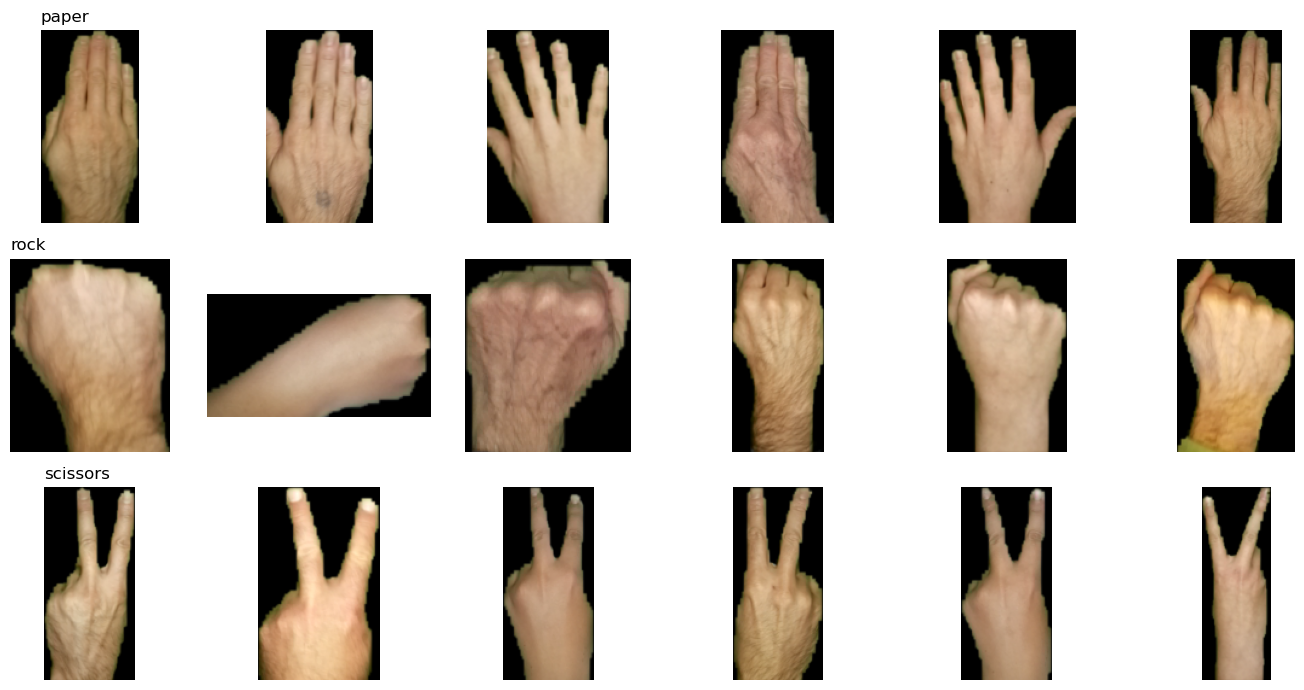

In [4]:
fig, ax = plt.subplots(3, 6, figsize=(14, 7))
for r, c in enumerate(CLASSES):
    for j in range(6):
        cut = dlonie[c][rng.integers(len(dlonie[c]))]
        pod = (cut[..., :3].astype(np.float32) * (cut[..., 3:] / 255.0)).astype(np.uint8)
        ax[r, j].imshow(pod); ax[r, j].axis("off")
    ax[r, 0].set_title(c, loc="left")
plt.tight_layout(); plt.show()

## 3. Tła

Mieszamy trzy źródła:
- **fragmenty prawdziwych zdjęć**: `flower_photos` z TensorFlow (liście, niebo, ziemia, ściany),
  pobierane automatycznie,
- **Twój folder `BG_DIR`**, jeśli go podasz (najlepiej zdjęcia wnętrz),
- **tła generowane**: ściana + blat, gradienty, rozmyte przedmioty, tkaniny.

In [5]:
def lista_zdjec(folder):
    ext = ("*.jpg", "*.jpeg", "*.png", "*.JPG", "*.JPEG", "*.PNG")
    return [p for e in ext for p in glob.glob(os.path.join(folder, "**", e), recursive=True)]

zdjecia_tla = []
if POBIERZ_ZDJECIA_TLA:
    try:
        p = keras.utils.get_file(
            "flower_photos.tgz",
            "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz",
            extract=True)
        zdjecia_tla += [f for f in lista_zdjec(os.path.dirname(p)) if "flower_photos" in f]
    except Exception as e:
        print("Nie udało się pobrać zdjęć na tła (zostają tła generowane):", e)
if BG_DIR and os.path.isdir(BG_DIR):
    zdjecia_tla += lista_zdjec(BG_DIR)
print("Zdjęć dostępnych jako tła:", len(zdjecia_tla))

# wczytujemy do pamięci próbkę zdjęć (pomniejszonych), żeby nie czytać dysku w kółko
cache_tla = []
for p in random.sample(zdjecia_tla, min(LICZBA_ZDJEC_TLA, len(zdjecia_tla))):
    im = cv2.imread(p)
    if im is None:
        continue
    s = 260 / min(im.shape[:2])
    im = cv2.resize(im, None, fx=s, fy=s, interpolation=cv2.INTER_AREA)
    cache_tla.append(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))

def losowy_kolor():
    # przewaga stonowanych barw, jak we wnętrzach
    base = rng.uniform(40, 230)
    return np.clip(base + rng.normal(0, 35, 3), 0, 255)

def tlo_zdjecie():
    im = cache_tla[rng.integers(len(cache_tla))]
    s = rng.uniform(KADR, min(im.shape[:2]))
    y = rng.integers(0, im.shape[0] - int(s) + 1)
    x = rng.integers(0, im.shape[1] - int(s) + 1)
    crop = im[y:y + int(s), x:x + int(s)]
    out = cv2.resize(crop, (KADR, KADR), interpolation=cv2.INTER_AREA)
    if rng.random() < 0.5:
        out = cv2.GaussianBlur(out, (0, 0), rng.uniform(0.5, 3.0))  # tło poza ostrością
    return out

def tlo_generowane():
    t = rng.integers(5)
    yy, xx = np.mgrid[0:KADR, 0:KADR].astype(np.float32) / KADR
    if t == 0:      # ściana + blat
        horyzont = rng.uniform(0.3, 0.8)
        a, b = losowy_kolor(), losowy_kolor()
        out = np.where((yy > horyzont)[..., None], b, a).astype(np.float32)
        out += rng.normal(0, 6, out.shape)
    elif t == 1:    # gradient
        a, b = losowy_kolor(), losowy_kolor()
        kat = rng.uniform(0, 2 * np.pi)
        w = np.clip((xx * np.cos(kat) + yy * np.sin(kat) + 1) / 2, 0, 1)[..., None]
        out = a * (1 - w) + b * w
    elif t == 2:    # rozmyte przedmioty
        out = np.full((KADR, KADR, 3), losowy_kolor(), np.float32)
        for _ in range(rng.integers(3, 9)):
            c = tuple(float(v) for v in losowy_kolor())
            if rng.random() < 0.5:
                cv2.ellipse(out, (int(rng.integers(KADR)), int(rng.integers(KADR))),
                            (int(rng.integers(15, 90)), int(rng.integers(15, 90))),
                            float(rng.uniform(0, 180)), 0, 360, c, -1)
            else:
                x0, y0 = rng.integers(-40, KADR, 2)
                cv2.rectangle(out, (int(x0), int(y0)), (int(x0 + rng.integers(20, 140)), int(y0 + rng.integers(20, 140))), c, -1)
        out = cv2.GaussianBlur(out, (0, 0), rng.uniform(2, 7))
    elif t == 3:    # tkanina / paski
        a, b = losowy_kolor(), losowy_kolor()
        f = rng.uniform(4, 25)
        kat = rng.uniform(0, np.pi)
        w = (np.sin((xx * np.cos(kat) + yy * np.sin(kat)) * f * 2 * np.pi) + 1) / 2
        out = a * (1 - w[..., None]) + b * w[..., None]
        out += rng.normal(0, 8, out.shape)
    else:           # plamy o niskiej częstotliwości
        n = int(rng.integers(3, 10))
        out = cv2.resize(rng.uniform(30, 230, (n, n, 3)).astype(np.float32), (KADR, KADR),
                         interpolation=cv2.INTER_CUBIC)
    return np.clip(out, 0, 255).astype(np.uint8)

def losowe_tlo():
    if cache_tla and rng.random() < 0.6:
        return tlo_zdjecie()
    return tlo_generowane()

Zdjęć dostępnych jako tła: 3670


## 4. Składanie sceny i udawanie kamery K10

In [6]:
def obroc(rgba, kat):
    h, w = rgba.shape[:2]
    M = cv2.getRotationMatrix2D((w / 2, h / 2), kat, 1.0)
    cos, sin = abs(M[0, 0]), abs(M[0, 1])
    nw, nh = int(h * sin + w * cos), int(h * cos + w * sin)
    M[0, 2] += nw / 2 - w / 2
    M[1, 2] += nh / 2 - h / 2
    out = cv2.warpAffine(rgba, M, (nw, nh), flags=cv2.INTER_LINEAR, borderValue=(0, 0, 0, 0))
    ys, xs = np.where(out[..., 3] > 8)
    return out[ys.min():ys.max() + 1, xs.min():xs.max() + 1]

def wklej(tlo, rgba, x, y):
    """Wkleja rgba w tło z lewym górnym rogiem w (x, y); fragmenty poza kadrem są obcinane."""
    H, W = tlo.shape[:2]
    h, w = rgba.shape[:2]
    x0, y0, x1, y1 = max(x, 0), max(y, 0), min(x + w, W), min(y + h, H)
    if x1 <= x0 or y1 <= y0:
        return tlo
    fg = rgba[y0 - y:y1 - y, x0 - x:x1 - x]
    a = fg[..., 3:4].astype(np.float32) / 255.0
    out = tlo.astype(np.float32)
    out[y0:y1, x0:x1] = out[y0:y1, x0:x1] * (1 - a) + fg[..., :3] * a
    return out

def scena(dlon):
    tlo = losowe_tlo()
    d = dlon
    if rng.random() < 0.5:
        d = d[:, ::-1]                                # lewa / prawa ręka
    # kierunek wejścia ręki: najczęściej od dołu, czasem z boku lub z góry
    k = rng.choice([0, 1, 3, 2], p=[0.7, 0.12, 0.12, 0.06])
    d = np.ascontiguousarray(np.rot90(d, k))
    d = obroc(d, rng.uniform(-30, 30))

    # rozmiar: dłuższy bok dłoni = 55–110% kadru (część ręki może wyjść poza kadr)
    s = rng.uniform(0.55, 1.1) * KADR / max(d.shape[:2])
    d = cv2.resize(d, None, fx=s, fy=s, interpolation=cv2.INTER_AREA if s < 1 else cv2.INTER_LINEAR)
    h, w = d.shape[:2]
    # ręka przylega do krawędzi, z której wchodzi (po obrotach "dół" jest po stronie k)
    wysun = rng.uniform(0.0, 0.25)
    cx = rng.uniform(0.3, 0.7) * KADR
    if k == 0:   x, y = int(cx - w / 2), int(KADR - h + wysun * h)          # od dołu
    elif k == 2: x, y = int(cx - w / 2), int(-wysun * h)                     # od góry
    elif k == 1: x, y = int(KADR - w + wysun * w), int(cx - h / 2)          # z prawej
    else:        x, y = int(-wysun * w), int(cx - h / 2)                     # z lewej
    return wklej(tlo, d, x, y)

def udawaj_k10(img):
    """img: float32 RGB 240x240 -> uint8 RGB 96x96, jak po przetworzeniu na płytce."""
    x = img / 255.0
    x = x * rng.uniform(0.8, 1.2, 3)                        # balans bieli
    x = np.clip(x * rng.uniform(0.55, 1.35), 0, 1)          # ekspozycja
    x = x ** rng.uniform(0.7, 1.5)                          # gamma / krzywa sensora
    m = x.mean()
    x = np.clip((x - m) * rng.uniform(0.7, 1.15) + m, 0, 1) # kontrast
    if rng.random() < 0.3:                                  # niższe nasycenie
        g = x.mean(axis=2, keepdims=True)
        x = g + (x - g) * rng.uniform(0.4, 0.9)
    x = (x * 255).astype(np.float32)
    if rng.random() < 0.7:
        x = cv2.GaussianBlur(x, (0, 0), rng.uniform(0.4, 1.6))  # optyka / ostrość
    x = x + rng.normal(0, rng.uniform(1, 9), x.shape)           # szum sensora
    x = np.clip(x, 0, 255).astype(np.uint8)
    x = cv2.resize(x, (IMG, IMG), interpolation=cv2.INTER_AREA)  # uśrednianie bloków, jak w K10
    # redukcja do RGB565 i z powrotem do 8 bitów (r*255/31 itd.), jak na płytce
    r = np.round((x[..., 0] >> 3).astype(np.float32) * 255 / 31)
    g = np.round((x[..., 1] >> 2).astype(np.float32) * 255 / 63)
    b = np.round((x[..., 2] >> 3).astype(np.float32) * 255 / 31)
    return np.stack([r, g, b], -1).astype(np.uint8)

def generuj(lista_dloni, ile_na_dlon):
    X, y = [], []
    for ci, c in enumerate(CLASSES):
        for dlon in lista_dloni[c]:
            for _ in range(ile_na_dlon):
                X.append(udawaj_k10(scena(dlon)))
                y.append(ci)
    X, y = np.array(X), np.array(y)
    perm = rng.permutation(len(y))
    return X[perm], y[perm]

# podział na trening / walidację PO DŁONIACH (żeby walidacja była uczciwa)
dlonie_tr, dlonie_val = {}, {}
for c in CLASSES:
    lst = dlonie[c][:]
    random.shuffle(lst)
    n_val = int(len(lst) * CZESC_WALIDACJI)
    dlonie_val[c], dlonie_tr[c] = lst[:n_val], lst[n_val:]

X_val, y_val = generuj(dlonie_val, 3)       # mała, stała walidacja
print("Walidacja:", X_val.shape)

# Trening: sceny składane NA BIEŻĄCO, bez trzymania tysięcy zdjęć w RAM-ie.
# Każda epoka dostaje nowe, losowe sceny (to dodatkowo pomaga modelowi).
pary_tr = [(ci, d) for ci, c in enumerate(CLASSES) for d in dlonie_tr[c]]

def generator_treningu():
    lista = pary_tr[:]
    while True:
        random.shuffle(lista)
        for ci, d in lista:
            yield udawaj_k10(scena(d)), ci

KROKI_NA_EPOKE = len(pary_tr) * WARIANTY_NA_DLON // BATCH
print("Dłoni treningowych:", len(pary_tr), "| kroków na epokę:", KROKI_NA_EPOKE)

Walidacja: (978, 96, 96, 3)
Dłoni treningowych: 1862 | kroków na epokę: 232


Podgląd: tak mniej więcej model zobaczy obraz z K10. Warto przejrzeć, czy dłonie są dobrze wycięte.

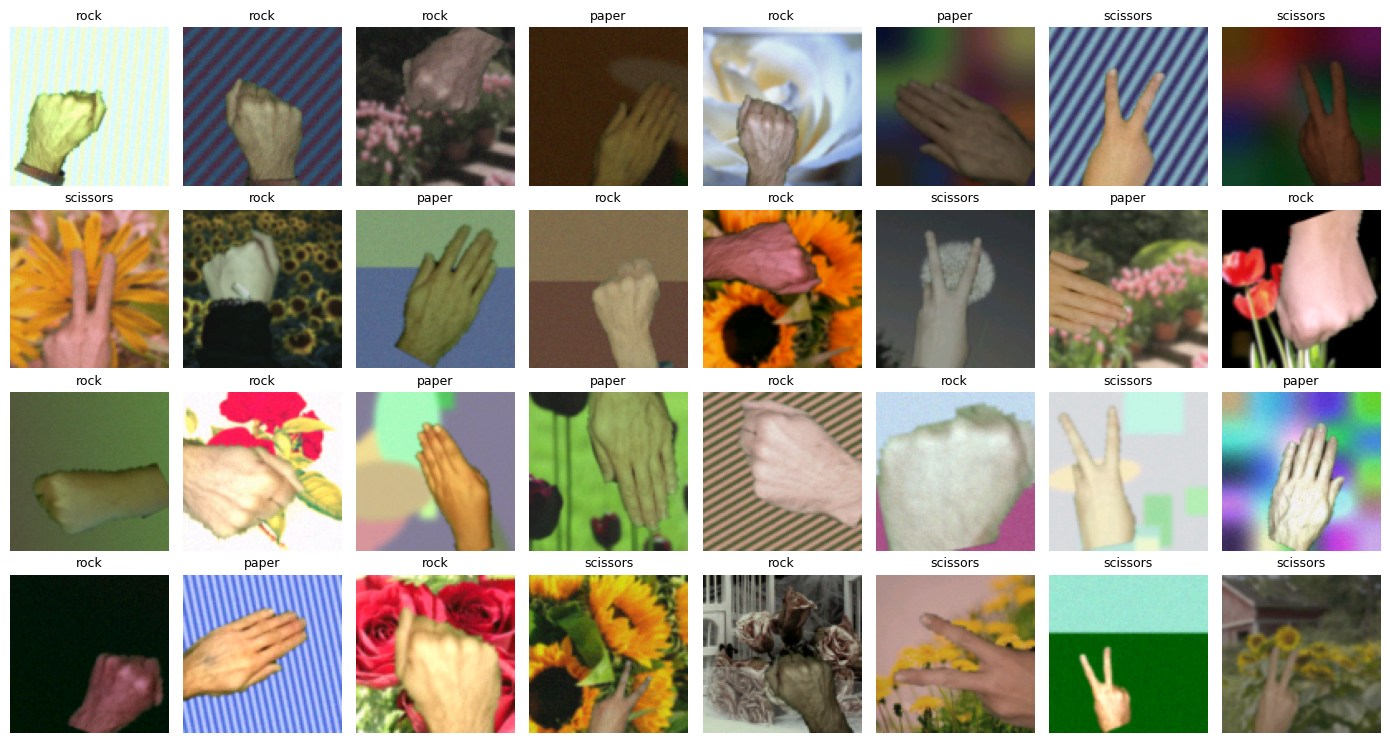

In [7]:
fig, ax = plt.subplots(4, 8, figsize=(14, 7.5))
for i, a in enumerate(ax.flat):
    ci, d = pary_tr[rng.integers(len(pary_tr))]
    a.imshow(udawaj_k10(scena(d))); a.set_title(CLASSES[ci], fontsize=9); a.axis("off")
plt.tight_layout(); plt.show()

## 5. Dane dla Keras (+ lekka augmentacja w locie)

In [8]:
AUTOTUNE = tf.data.AUTOTUNE
onehot = lambda y: tf.one_hot(y, len(CLASSES))

aug = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.04),
    layers.RandomZoom((-0.05, 0.1)),
    layers.RandomTranslation(0.05, 0.05),
])

def przygotuj(x, y):
    return tf.cast(x, tf.float32), onehot(y)

train_aug = (tf.data.Dataset.from_generator(
                 generator_treningu,
                 output_signature=(tf.TensorSpec((IMG, IMG, 3), tf.uint8), tf.TensorSpec((), tf.int32)))
             .map(przygotuj).batch(BATCH)
             .map(lambda x, y: (aug(x, training=True), y), num_parallel_calls=AUTOTUNE)
             .prefetch(AUTOTUNE))
val_b = tf.data.Dataset.from_tensor_slices((X_val, y_val)).map(przygotuj).batch(BATCH).prefetch(AUTOTUNE)

E0000 00:00:1793915879.203330 1775171 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


## 6. Model (tak samo jak w zwykłym notebooku)

In [9]:
base = keras.applications.MobileNetV2(
    input_shape=(IMG, IMG, 3), alpha=ALPHA, include_top=False, weights="imagenet")
base.trainable = False

inputs = keras.Input((IMG, IMG, 3))
x = layers.Rescaling(1 / 127.5, offset=-1)(inputs)
x = base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(len(CLASSES), activation="softmax")(x)
model = keras.Model(inputs, outputs)

## 7. Trening: etap 1 (głowica) i etap 2 (dostrajanie)

In [10]:
cb = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True)]
model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="categorical_crossentropy", metrics=["accuracy"])
model.fit(train_aug, steps_per_epoch=KROKI_NA_EPOKE, validation_data=val_b, epochs=EPOCHS_HEAD, callbacks=cb)

base.trainable = True
for layer in base.layers[:-40]:
    layer.trainable = False
for layer in base.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False
model.compile(optimizer=keras.optimizers.Adam(1e-4), loss="categorical_crossentropy", metrics=["accuracy"])
model.fit(train_aug, steps_per_epoch=KROKI_NA_EPOKE, validation_data=val_b, epochs=EPOCHS_FINE, callbacks=cb)

Epoch 1/12


/opt/conda/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1793915887.057337 1775171 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.


232/232 ━━━━━━━━━━━━━━━━━━━━ 329s 1s/step - accuracy: 0.6857 - loss: 0.7346 - val_accuracy: 0.7740 - val_loss: 0.5580
Epoch 2/12
232/232 ━━━━━━━━━━━━━━━━━━━━ 316s 1s/step - accuracy: 0.7879 - loss: 0.5228 - val_accuracy: 0.7843 - val_loss: 0.5399
Epoch 3/12
232/232 ━━━━━━━━━━━━━━━━━━━━ 312s 1s/step - accuracy: 0.8005 - loss: 0.4910 - val_accuracy: 0.7975 - val_loss: 0.4826
Epoch 4/12
232/232 ━━━━━━━━━━━━━━━━━━━━ 314s 1s/step - accuracy: 0.8091 - loss: 0.4846 - val_accuracy: 0.8067 - val_loss: 0.5109
Epoch 5/12
232/232 ━━━━━━━━━━━━━━━━━━━━ 319s 1s/step - accuracy: 0.8124 - loss: 0.4683 - val_accuracy: 0.7975 - val_loss: 0.5210
Epoch 6/12
232/232 ━━━━━━━━━━━━━━━━━━━━ 313s 1s/step - accuracy: 0.8054 - loss: 0.4729 - val_accuracy: 0.8129 - val_loss: 0.4580
Epoch 7/12
232/232 ━━━━━━━━━━━━━━━━━━━━ 311s 1s/step - accuracy: 0.8182 - loss: 0.4564 - val_accuracy: 0.8047 - val_loss: 0.4961
Epoch 8/12
232/232 ━━━━━━━━━━━━━━━━━━━━ 315s 1s/step - accuracy: 0.8161 - loss: 0.4623 - val_accuracy: 0.824

## 8. Ocena (float32) na sztucznych zdjęciach z nieznanych dłoni

In [11]:
model.save(os.path.join(OUT_DIR, "model.keras"))
print("Zapisano model.keras w", OUT_DIR)

Zapisano model.keras w .


In [12]:
y_pred = np.argmax(model.predict(val_b, verbose=0), 1)
print(classification_report(y_val, y_pred, target_names=CLASSES, digits=3))
print(confusion_matrix(y_val, y_pred))

              precision    recall  f1-score   support

       paper      0.913     0.921     0.917       318
        rock      0.909     0.985     0.945       324
    scissors      0.961     0.875     0.916       336

    accuracy                          0.926       978
   macro avg      0.927     0.927     0.926       978
weighted avg      0.928     0.926     0.926       978

[[293  17   8]
 [  1 319   4]
 [ 27  15 294]]


## 9. Kwantyzacja INT8

In [16]:
def representative_data():
    gen = generator_treningu()
    for _ in range(300):
        x, _ = next(gen)
        yield [x[None].astype(np.float32)]

conv = tf.lite.TFLiteConverter.from_keras_model(model)
conv.optimizations = [tf.lite.Optimize.DEFAULT]
conv.representative_dataset = representative_data
conv.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
conv.inference_input_type = tf.int8
conv.inference_output_type = tf.int8
# TFLite Micro na K10 nie obsługuje kwantyzacji "per-channel" w warstwie Dense
conv._experimental_disable_per_channel_quantization_for_dense_layers = True
tflite_model = conv.convert()
with open(os.path.join(OUT_DIR, "rps_int8.tflite"), "wb") as f:
    f.write(tflite_model)
print(f"Model INT8: {len(tflite_model) / 1024:.0f} KB")

INFO:tensorflow:Assets written to: /tmp/tmpymes6k83/assets


INFO:tensorflow:Assets written to: /tmp/tmpymes6k83/assets


Saved artifact at '/tmp/tmpymes6k83'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 96, 96, 3), dtype=tf.float32, name='keras_tensor_159')
Output Type:
  TensorSpec(shape=(None, 3), dtype=tf.float32, name=None)
Captures:
  140115865356432: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140115865358736: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140115865358928: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140115865358160: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140115865357392: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140115865359120: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140115865361040: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140115865361232: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140115865360080: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140115865359504: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140115865358

/opt/conda/lib/python3.11/site-packages/tensorflow/lite/python/convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
W0000 00:00:1793958862.405703 1775171 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1793958862.405770 1775171 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
I0000 00:00:1793958862.406162 1775171 reader.cc:83] Reading SavedModel from: /tmp/tmpymes6k83
I0000 00:00:1793958862.436223 1775171 reader.cc:52] Reading meta graph with tags { serve }
I0000 00:00:1793958862.436288 1775171 reader.cc:147] Reading SavedModel debug info (if present) from: /tmp/tmpymes6k83
I0000 00:00:1793958862.767520 1775171 loader.cc:236] Restoring SavedModel bundle.
I0000 00:00:1793958864.497687 1775171 loader.cc:220] Running initialization op on SavedModel bundle at path: /tmp/tmpymes6k83
I0000 00:00:1793958864.917015 1775171 loader.cc:471] SavedModel load for tags { serve }; Statu

Model INT8: 631 KB


## 10. Sprawdzenie modelu INT8

Najpierw na sztucznej walidacji. Jeśli podasz `K10_TEST_DIR`, także na prawdziwych zdjęciach
z K10. Tylko ten drugi wynik naprawdę mówi, jak model poradzi sobie na płytce.

In [17]:
interp = tf.lite.Interpreter(model_content=tflite_model)
interp.allocate_tensors()
inp, out = interp.get_input_details()[0], interp.get_output_details()[0]
in_scale, in_zp = inp["quantization"]
print("Operacje w modelu:", sorted({op["op_name"] for op in interp._get_ops_details()} - {"DELEGATE"}))

def int8_predict(img_uint8):
    q = np.clip(np.round(img_uint8.astype(np.float32) / in_scale + in_zp), -128, 127).astype(np.int8)
    interp.set_tensor(inp["index"], q[None])
    interp.invoke()
    return int(np.argmax(interp.get_tensor(out["index"])[0]))

acc = np.mean([int8_predict(x) == y for x, y in zip(X_val, y_val)])
print(f"INT8, sztuczna walidacja: {acc:.3f}")

if K10_TEST_DIR and os.path.isdir(K10_TEST_DIR):
    ok = n = 0
    for ci, c in enumerate(CLASSES):
        for p in lista_zdjec(os.path.join(K10_TEST_DIR, c)):
            im = cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB)
            h, w = im.shape[:2]; s = min(h, w)
            im = im[(h - s) // 2:(h - s) // 2 + s, (w - s) // 2:(w - s) // 2 + s]
            im = cv2.resize(im, (IMG, IMG), interpolation=cv2.INTER_AREA)
            ok += int8_predict(im) == ci; n += 1
    if n:
        print(f"INT8, PRAWDZIWE zdjęcia z K10: {ok / n:.3f}  ({ok}/{n})")

Operacje w modelu: ['ADD', 'CONV_2D', 'DEPTHWISE_CONV_2D', 'FULLY_CONNECTED', 'MEAN', 'MUL', 'SOFTMAX']


/opt/conda/lib/python3.11/site-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


INT8, sztuczna walidacja: 0.887


## 11. Eksport `model_data.h`

Pobierz `model_data.h` z zakładki *Output* i podmień nim plik w folderze `3_k10_rps/`.

In [18]:
def write_header(data, path):
    lines = ["  " + ", ".join(f"0x{b:02x}" for b in data[i:i + 16]) + "," for i in range(0, len(data), 16)]
    labels = ", ".join(f'"{c}"' for c in CLASSES)
    with open(path, "w") as f:
        f.write("// Wygenerowane automatycznie przez notebook trenujący. Nie edytuj ręcznie.\n")
        f.write("#pragma once\n#include <stdint.h>\n\n")
        f.write(f"#define MODEL_IMG {IMG}\n#define MODEL_NUM_CLASSES {len(CLASSES)}\n")
        f.write(f"static const char* const MODEL_LABELS[MODEL_NUM_CLASSES] = {{{labels}}};\n\n")
        f.write("alignas(16) const uint8_t g_model[] = {\n" + "\n".join(lines) + "\n};\n")
        f.write(f"const unsigned int g_model_len = {len(data)};\n")

write_header(tflite_model, os.path.join(OUT_DIR, "model_data.h"))
print("Zapisano", os.path.join(OUT_DIR, "model_data.h"))

Zapisano ./model_data.h
